# Sentiment Analysis (RNN , LSTM ,GRU , BiDirectional)

In [10]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
device

PyTorch: 2.14.0+cpu
CUDA available: False


device(type='cpu')

In [11]:
dataset = load_dataset("stanfordnlp/imdb")

In [12]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [13]:
original_train = dataset["train"]
original_test = dataset["test"]

print("Original train:", len(original_train))
print("Original test:", len(original_test))

Original train: 25000
Original test: 25000


In [14]:
def remove_duplicates(split):

    seen = set()
    keep_indices = []

    for i, text in enumerate(split["text"]):

        if text not in seen:
            seen.add(text)
            keep_indices.append(i)

    return split.select(keep_indices)

In [15]:
clean_train = remove_duplicates(original_train)
clean_test = remove_duplicates(original_test)

print("Train before:", len(original_train))
print("Train after dedup:", len(clean_train))

print()

print("Test before:", len(original_test))
print("Test after dedup:", len(clean_test))

Train before: 25000
Train after dedup: 24904

Test before: 25000
Test after dedup: 24801


In [16]:
print("Train:", len(clean_train))
print("Test:", len(clean_test))
print("Unsupervised:", len(dataset["unsupervised"]))

print(dataset["train"].features)

Train: 24904
Test: 24801
Unsupervised: 50000
{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}


In [17]:
print("\nFeatures:")
print(clean_train.features)

print("\nLabels:")
print(clean_train.features["label"].names)


Features:
{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

Labels:
['neg', 'pos']


In [18]:
# balance of dataset
#50% 50%
train_labels = clean_train["label"]                
pd.Series(train_labels).value_counts()


1    12472
0    12432
Name: count, dtype: int64

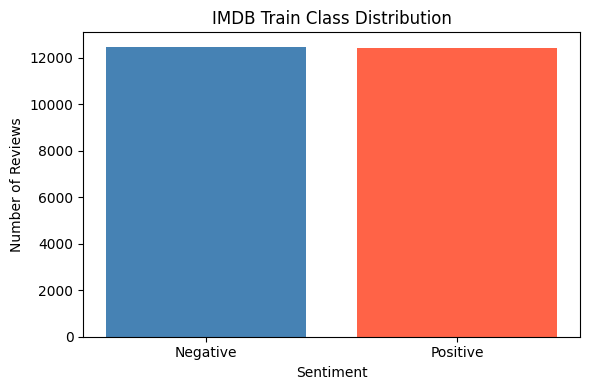

In [19]:
labels = ["Negative", "Positive"]
counts = (
    pd.Series(train_labels)
    .value_counts()
    .tolist()
)

plt.figure(figsize=(6, 4))
plt.bar(labels, counts, color=["steelblue", "tomato"])
plt.title("IMDB Train Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [20]:
train_val_split = clean_train.train_test_split(
    test_size=0.2,
    seed=42,
    stratify_by_column="label"
)
train_val_split

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 19923
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 4981
    })
})

In [21]:
train_dataset = train_val_split["train"]
val_dataset = train_val_split["test"]

test_dataset = clean_test

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

val_counts=pd.Series(val_dataset["label"]).value_counts()
val_counts

Train: 19923
Validation: 4981
Test: 24801


1    2495
0    2486
Name: count, dtype: int64

In [22]:
def check_nulls(split, split_name):

    texts = split["text"]
    labels = split["label"]

    null_texts = sum(text is None for text in texts)
    null_labels = sum(label is None for label in labels)

    print(f"{split_name}:")
    print("Null texts:", null_texts)
    print("Null labels:", null_labels)

check_nulls(train_dataset, "Train")
print()

check_nulls(val_dataset, "Validation")
print()

check_nulls(test_dataset, "Test")

Train:
Null texts: 0
Null labels: 0

Validation:
Null texts: 0
Null labels: 0

Test:
Null texts: 0
Null labels: 0


In [23]:
def check_empty_reviews(split, split_name):

    empty_count = sum(
        len(text.strip()) == 0
        for text in split["text"]
    )

    print(f"{split_name} empty reviews: {empty_count}")

check_empty_reviews(train_dataset, "Train")
check_empty_reviews(val_dataset, "Validation")
check_empty_reviews(test_dataset, "Test")

Train empty reviews: 0
Validation empty reviews: 0
Test empty reviews: 0


In [24]:
def check_duplicates(split, split_name):

    texts = split["text"]

    unique_texts = set(texts)

    duplicate_count = len(texts) - len(unique_texts)

    print(f"{split_name}:")
    print("Total reviews:", len(texts))
    print("Unique reviews:", len(unique_texts))
    print("Duplicate reviews:", duplicate_count)

check_duplicates(train_dataset, "Train")
print()

check_duplicates(val_dataset, "Validation")
print()

check_duplicates(test_dataset, "Test")

Train:
Total reviews: 19923
Unique reviews: 19923
Duplicate reviews: 0

Validation:
Total reviews: 4981
Unique reviews: 4981
Duplicate reviews: 0

Test:
Total reviews: 24801
Unique reviews: 24801
Duplicate reviews: 0


In [25]:
test_texts = set(test_dataset["text"])
#removing overlap because data leakage does not happen
val_before = len(val_dataset)
val_dataset = val_dataset.filter(
    lambda example: example["text"] not in test_texts
)

val_texts = set(val_dataset["text"])
train_before = len(train_dataset)
excluded_texts = test_texts | val_texts
train_dataset = train_dataset.filter(
    lambda example: example["text"] not in excluded_texts
)

train_texts = set(train_dataset["text"])

train_val_overlap = train_texts.intersection(val_texts)
train_test_overlap = train_texts.intersection(test_texts)
val_test_overlap = val_texts.intersection(test_texts)

print("Train reviews removed:", train_before - len(train_dataset))
print("Validation reviews removed:", val_before - len(val_dataset))
print("Train ↔ Validation overlap:", len(train_val_overlap))
print("Train ↔ Test overlap:", len(train_test_overlap))
print("Validation ↔ Test overlap:", len(val_test_overlap))

Train reviews removed: 96
Validation reviews removed: 27
Train ↔ Validation overlap: 0
Train ↔ Test overlap: 0
Validation ↔ Test overlap: 0


# Phase 2 — EDA

In [26]:
train_lengths = [
    len(text.split())
    for text in train_dataset["text"]
]

print("Number of train reviews:", len(train_lengths))
print("First 10 lengths:", train_lengths[:10])

Number of train reviews: 19827
First 10 lengths: [282, 325, 927, 98, 142, 205, 208, 67, 155, 468]


In [27]:
print("Minimum length:", np.min(train_lengths))
print("Maximum length:", np.max(train_lengths))
print(f"Mean length: {np.mean(train_lengths):.2f}")
print("Median length:", np.median(train_lengths))

Minimum length: 10
Maximum length: 2470
Mean length: 234.62
Median length: 175.0


In [28]:
percentiles = [75, 90, 95, 99]

for p in percentiles:
    value = np.percentile(train_lengths, p)

    print(
        f"{p}th percentile: {value:.0f} words"
    )

75th percentile: 286 words
90th percentile: 460 words
95th percentile: 599 words
99th percentile: 911 words


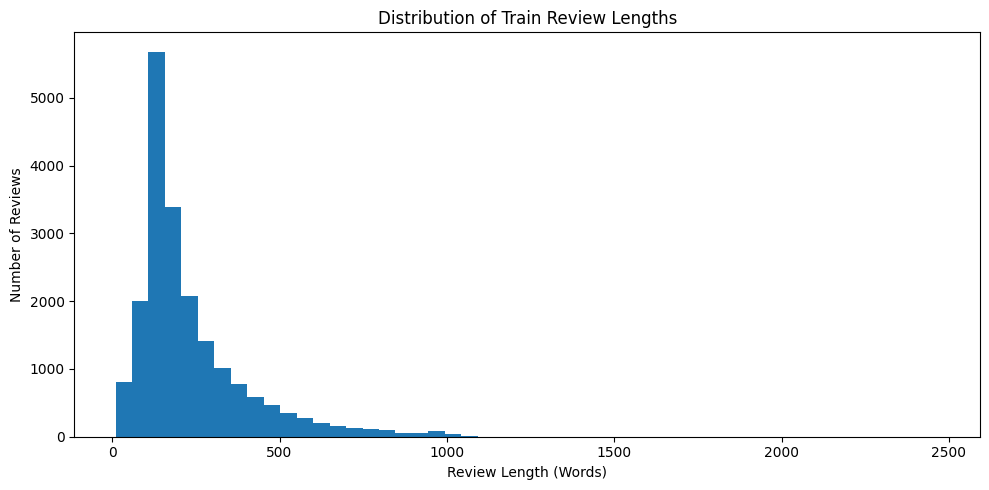

In [29]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_lengths,
    bins=50
)

plt.title("Distribution of Train Review Lengths")
plt.xlabel("Review Length (Words)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [30]:
short_reviews = sum(
    length < 20
    for length in train_lengths
)

long_reviews = sum(
    length > 1000
    for length in train_lengths
)

print("Reviews shorter than 20 words:", short_reviews)
print("Reviews longer than 1000 words:", long_reviews)

Reviews shorter than 20 words: 8
Reviews longer than 1000 words: 41


In [31]:
negative_lengths = []
positive_lengths = []

for sample in train_dataset:

    length = len(sample["text"].split())

    if sample["label"] == 0:
        negative_lengths.append(length)

    else:
        positive_lengths.append(length)

print("NEGATIVE REVIEWS")
print("----------------")
print("Count:", len(negative_lengths))
print(f"Mean: {np.mean(negative_lengths):.2f}")
print(f"Median: {np.median(negative_lengths):.2f}")

print()

print("POSITIVE REVIEWS")
print("----------------")
print("Count:", len(positive_lengths))
print(f"Mean: {np.mean(positive_lengths):.2f}")
print(f"Median: {np.median(positive_lengths):.2f}")

NEGATIVE REVIEWS
----------------
Count: 9871
Mean: 231.60
Median: 175.00

POSITIVE REVIEWS
----------------
Count: 9956
Mean: 237.61
Median: 175.00


In [32]:
length_comparison = pd.DataFrame({
    "Sentiment": ["Negative", "Positive"],
    "Count": [
        len(negative_lengths),
        len(positive_lengths)
    ],
    "Mean Length": [
        np.mean(negative_lengths),
        np.mean(positive_lengths)
    ],
    "Median Length": [
        np.median(negative_lengths),
        np.median(positive_lengths)
    ],
    "Max Length": [
        np.max(negative_lengths),
        np.max(positive_lengths)
    ]
})

length_comparison

,Sentiment,Count,Mean Length,Median Length,Max Length
0,Negative,9871,231.601155,175.0,1522
1,Positive,9956,237.610285,175.0,2470


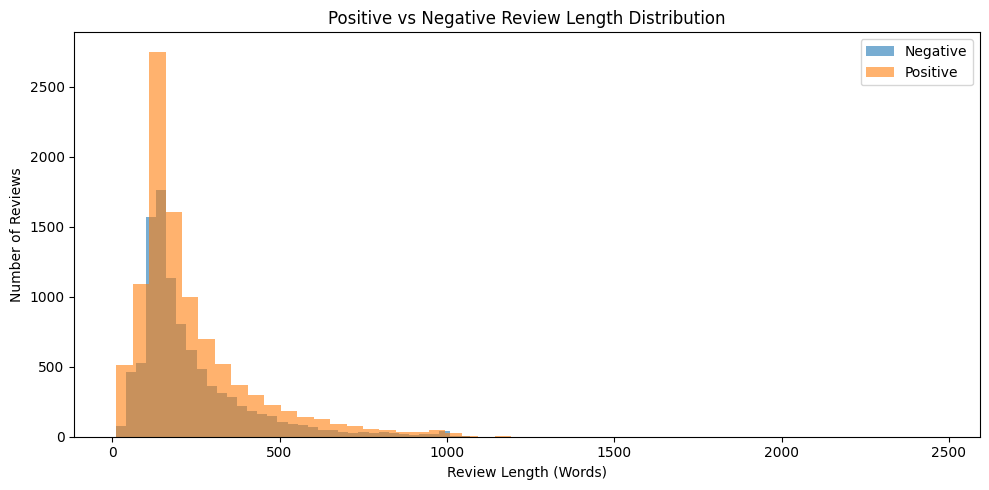

In [33]:
plt.figure(figsize=(10, 5))

plt.hist(
    negative_lengths,
    bins=50,
    alpha=0.6,
    label="Negative"
)

plt.hist(
    positive_lengths,
    bins=50,
    alpha=0.6,
    label="Positive"
)

plt.title("Positive vs Negative Review Length Distribution")
plt.xlabel("Review Length (Words)")
plt.ylabel("Number of Reviews")

plt.legend()

plt.tight_layout()
plt.show()

In [34]:
html_count = sum(
    "<br" in text.lower()
    for text in train_dataset["text"]
)

html_percentage = (
    html_count / len(train_dataset) * 100
)

print("Reviews containing <br>:", html_count)

print(
    f"Percentage: {html_percentage:.2f}%"
)

Reviews containing <br>: 11630
Percentage: 58.66%


In [35]:
uppercase_examples = []

for text in train_dataset["text"]:

    words = text.split()

    uppercase_words = [
        word
        for word in words
        if word.isupper()
        and len(word) > 2
    ]

    if uppercase_words:

        uppercase_examples.append(
            (text, uppercase_words[:10])
        )

    if len(uppercase_examples) == 5:
        break

for i, (text, words) in enumerate(
    uppercase_examples,
    start=1
):

    print("=" * 80)

    print(f"Example {i}")
    print("Uppercase words:", words)

    print()
    print(text[:1000])

    print()

Example 1
Uppercase words: ['KFC', 'KFC']

Isabel Allende's magical, lyrical novel about three generations of an aristocratic South American family was vandalized. The lumbering oaf of a movie that resulted--largely due to a magnificent cast of Anglo actors completely unable to carry off the evasive Latin mellifluousness of Allende's characters, and a plodding Scandinavian directorial hand--was so uncomfortable in its own skin that I returned to the theater a second time to make certain I had not missed something vital that might change my opinion. To my disappointment, I had not missed a thing. None among Meryl Streep, Jeremy Irons, Glenn Close and Vanessa Redgrave could wiggle free of the trap set for them by director Bille August. All of them looked perfectly stiff and resigned, as if, by putting forth as little effort as possible, they expected to fade unnoticed into lovely period sets. (Yes, the film was art directed within an inch of its life.) Curious that the production designe

In [36]:
contractions = [
    "don't",
    "didn't",
    "wasn't",
    "isn't",
    "can't",
    "couldn't",
    "wouldn't",
    "won't"
]

In [37]:
for contraction in contractions:

    count = sum(
        contraction in text.lower()
        for text in train_dataset["text"]
    )

    print(
        f"{contraction}: {count}"
    )

don't: 4986
didn't: 2729
wasn't: 1533
isn't: 2079
can't: 2376
couldn't: 1070
wouldn't: 772
won't: 877


In [38]:
reviews_with_numbers = sum(

    any(char.isdigit() for char in text)

    for text in train_dataset["text"]
)

print(
    "Reviews containing numbers:",
    reviews_with_numbers
)

print(
    f"Percentage: "
    f"{reviews_with_numbers / len(train_dataset) * 100:.2f}%"
)

Reviews containing numbers: 11195
Percentage: 56.46%


In [39]:
patterns = [
    "!!!",
    "???",
    "..."
]

for pattern in patterns:

    count = sum(
        pattern in text
        for text in train_dataset["text"]
    )

    print(
        f"{pattern}: {count} reviews"
    )

!!!: 763 reviews
???: 217 reviews
...: 4411 reviews


In [40]:
from collections import Counter

word_counts = Counter()

for text in train_dataset["text"]:

    words = text.split()

    word_counts.update(words)

In [41]:
total_words = sum(word_counts.values())
print("Total word occurrences:", total_words)


Total word occurrences: 4651783


In [42]:
vocab_size = len(word_counts)

print("Raw vocabulary size:", vocab_size)

Raw vocabulary size: 243612


In [43]:
most_common_words = word_counts.most_common(30)

for word, count in most_common_words:

    print(
        f"{word:<20} {count}"
    )

the                  228803
a                    123149
and                  121528
of                   113838
to                   105420
is                   82159
in                   68086
I                    52372
that                 51465
this                 45376
it                   43241
/><br                40515
was                  36960
as                   33970
with                 33268
for                  32696
The                  26856
but                  26772
on                   24479
movie                24232
are                  22853
his                  21981
film                 21695
have                 21597
not                  20874
be                   20256
you                  20046
he                   17331
by                   17077
at                   16947


In [44]:
lower_word_counts = Counter()

for text in train_dataset["text"]:

    words = text.lower().split()

    lower_word_counts.update(words)

In [45]:
print(
    "Raw vocabulary size:",
    len(word_counts)
)

print(
    "Lowercase vocabulary size:",
    len(lower_word_counts)
)

Raw vocabulary size: 243612
Lowercase vocabulary size: 218806


In [46]:
words_once = sum(
    count == 1
    for count in lower_word_counts.values()
)

print(
    "Words appearing once:",
    words_once
)

Words appearing once: 131549


In [47]:
thresholds = [1, 2, 3, 5, 10, 20]

for min_freq in thresholds:

    size = sum(
        count >= min_freq
        for count in lower_word_counts.values()
    )

    print(
        f"min_freq >= {min_freq}: "
        f"{size} words"
    )

min_freq >= 1: 218806 words
min_freq >= 2: 87257 words
min_freq >= 3: 60294 words
min_freq >= 5: 39824 words
min_freq >= 10: 23197 words
min_freq >= 20: 13528 words


In [48]:
frequency_groups = {
    "1 time": 0,
    "2-4 times": 0,
    "5-9 times": 0,
    "10-99 times": 0,
    "100+ times": 0
}

for count in lower_word_counts.values():

    if count == 1:

        frequency_groups["1 time"] += 1

    elif count <= 4:

        frequency_groups["2-4 times"] += 1

    elif count <= 9:

        frequency_groups["5-9 times"] += 1

    elif count <= 99:

        frequency_groups["10-99 times"] += 1

    else:

        frequency_groups["100+ times"] += 1

In [49]:
for group, count in frequency_groups.items():

    print(
        f"{group:<15}: {count}"
    )

1 time         : 131549
2-4 times      : 47433
5-9 times      : 16627
10-99 times    : 19677
100+ times     : 3520


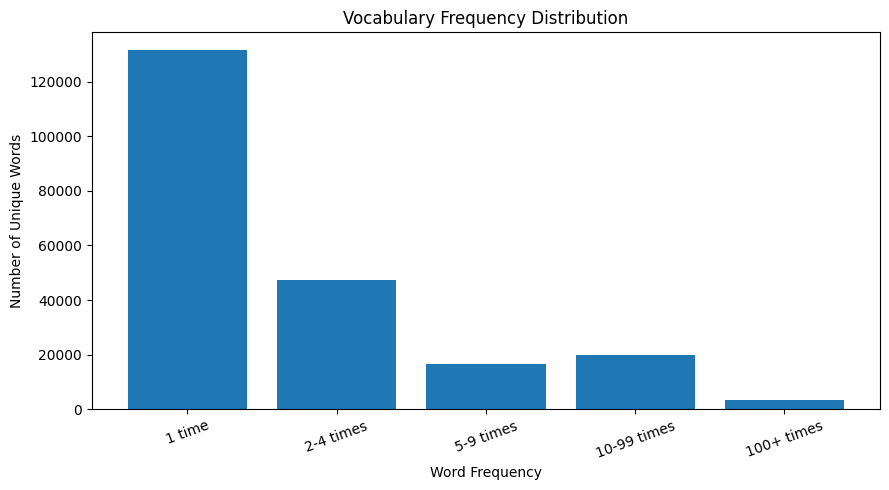

In [50]:
plt.figure(figsize=(9, 5))

plt.bar(
    frequency_groups.keys(),
    frequency_groups.values()
)

plt.title("Vocabulary Frequency Distribution")

plt.xlabel("Word Frequency")

plt.ylabel("Number of Unique Words")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [51]:
negative_word_counts = Counter()
positive_word_counts = Counter()


for sample in train_dataset:

    words = sample["text"].lower().split()

    if sample["label"] == 0:

        negative_word_counts.update(words)

    else:

        positive_word_counts.update(words)

In [52]:
print("MOST COMMON NEGATIVE WORDS")
print("-" * 40)

for word, count in negative_word_counts.most_common(30):

    print(
        f"{word:<20} {count}"
    )

MOST COMMON NEGATIVE WORDS
----------------------------------------
the                  124110
a                    61557
and                  56671
of                   54163
to                   53813
is                   38243
in                   33476
i                    29615
this                 29529
that                 26673
it                   25818
/><br                20709
was                  20136
for                  16760
but                  16059
with                 16054
as                   15635
movie                13806
on                   12511
not                  11971
have                 11898
are                  11339
you                  11104
be                   10985
film                 10366
his                  9640
he                   9420
at                   9389
they                 9224
one                  8619


In [53]:
print("MOST COMMON POSITIVE WORDS")
print("-" * 40)

for word, count in positive_word_counts.most_common(30):

    print(
        f"{word:<20} {count}"
    )

MOST COMMON POSITIVE WORDS
----------------------------------------
the                  132681
and                  69586
a                    65430
of                   60889
to                   52746
is                   44665
in                   38560
i                    26358
it                   26207
that                 26156
this                 25747
as                   20367
/><br                19806
with                 18014
for                  17332
was                  17082
but                  15579
his                  13434
on                   12669
are                  11701
film                 11626
he                   11505
you                  10920
not                  10753
movie                10721
have                 9884
be                   9414
by                   9368
one                  9364
an                   8915


In [54]:
import re

def exploratory_clean(text):
    
    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)
    
    text = text.lower()
    
    return text

In [55]:
sample_text = train_dataset[15001]["text"]

print("BEFORE:")
print(sample_text[:500])

print("\nAFTER:")
print(exploratory_clean(sample_text)[:500])

BEFORE:
OK, If you're looking for another Bastketball Diaries, this is completely the wrong film.<br /><br />I revolves around two brothers. Max, the younger, has a major cocaine addiction. Adam, the eldest, is a doctor. This movie is suppose to show the plunge from reality to the extreme lows that drugs make possible. It however, does not. It shows that cocaine can be fun no matter what the situation happens to be present. Most of the movie focus is on Max and his parting ways. Eventually Adam, can no 

AFTER:
ok, if you're looking for another bastketball diaries, this is completely the wrong film.  i revolves around two brothers. max, the younger, has a major cocaine addiction. adam, the eldest, is a doctor. this movie is suppose to show the plunge from reality to the extreme lows that drugs make possible. it however, does not. it shows that cocaine can be fun no matter what the situation happens to be present. most of the movie focus is on max and his parting ways. eventually adam, 

In [56]:
def exploratory_tokenize(text):
    
    text = exploratory_clean(text)
    
    tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?",
        text
    )
    
    return tokens

In [57]:
example = """
This movie wasn't GOOD!!! <br /><br />
I can't recommend it. 10/10
"""

print(exploratory_tokenize(example))

['this', 'movie', "wasn't", 'good', 'i', "can't", 'recommend', 'it']


In [58]:
from collections import Counter

clean_word_counts = Counter()

for text in train_dataset["text"]:
    
    tokens = exploratory_tokenize(text)
    
    clean_word_counts.update(tokens)

In [59]:
clean_total_words = sum(
    clean_word_counts.values()
)

clean_vocab_size = len(
    clean_word_counts
)

print(
    "Clean total word occurrences:",
    clean_total_words
)

print(
    "Clean vocabulary size:",
    clean_vocab_size
)

Clean total word occurrences: 4623171
Clean vocabulary size: 72636


In [60]:
print("Raw vocabulary size:")
print(len(word_counts))

print()

print("Lowercase vocabulary size:")
print(len(lower_word_counts))

print()

print("Clean vocabulary size:")
print(len(clean_word_counts))

Raw vocabulary size:
243612

Lowercase vocabulary size:
218806

Clean vocabulary size:
72636


In [61]:
clean_words_once = sum(
    count == 1
    for count in clean_word_counts.values()
)

print(
    "Clean words appearing once:",
    clean_words_once
)

Clean words appearing once: 27713


In [62]:
thresholds = [
    1,
    2,
    3,
    5,
    10,
    20
]

for min_freq in thresholds:

    size = sum(
        count >= min_freq
        for count in clean_word_counts.values()
    )

    print(
        f"min_freq >= {min_freq}: "
        f"{size} words"
    )

min_freq >= 1: 72636 words
min_freq >= 2: 44923 words
min_freq >= 3: 35628 words
min_freq >= 5: 26791 words
min_freq >= 10: 17936 words
min_freq >= 20: 11486 words


In [63]:
clean_frequency_groups = {
    "1 time": 0,
    "2-4 times": 0,
    "5-9 times": 0,
    "10-99 times": 0,
    "100+ times": 0
}

for count in clean_word_counts.values():

    if count == 1:
        clean_frequency_groups["1 time"] += 1

    elif count <= 4:
        clean_frequency_groups["2-4 times"] += 1

    elif count <= 9:
        clean_frequency_groups["5-9 times"] += 1

    elif count <= 99:
        clean_frequency_groups["10-99 times"] += 1

    else:
        clean_frequency_groups["100+ times"] += 1
        

In [64]:
for group, count in clean_frequency_groups.items():

    print(
        f"{group:<15}: {count}"
    )

1 time         : 27713
2-4 times      : 18132
5-9 times      : 8855
10-99 times    : 14390
100+ times     : 3546


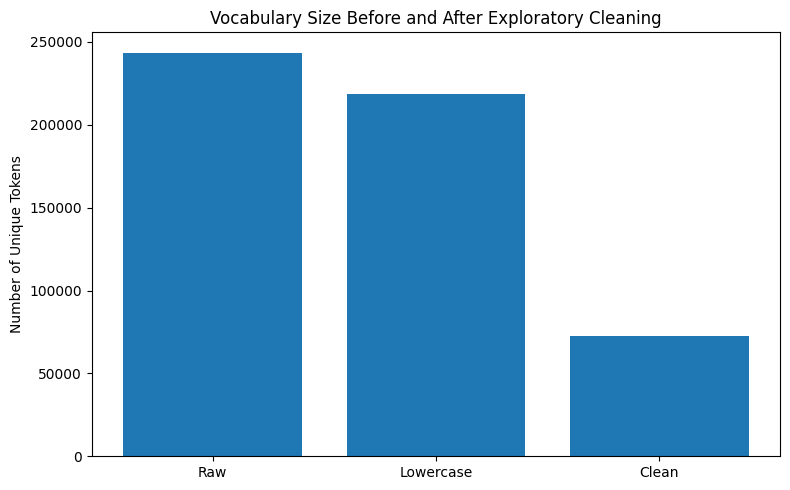

In [65]:
vocab_names = [
    "Raw",
    "Lowercase",
    "Clean"
]

vocab_sizes = [
    len(word_counts),
    len(lower_word_counts),
    len(clean_word_counts)
]

plt.figure(figsize=(8, 5))

plt.bar(
    vocab_names,
    vocab_sizes
)

plt.title(
    "Vocabulary Size Before and After Exploratory Cleaning"
)

plt.ylabel(
    "Number of Unique Tokens"
)

plt.tight_layout()

plt.show()

In [66]:
import re
from collections import Counter

rating_pattern = re.compile(
    r"\b(\d{1,2})\s*/\s*(10|100)\b"
)

ratings = []

for text in train_dataset["text"]:

    matches = rating_pattern.findall(text)

    for numerator, denominator in matches:
        ratings.append(
            f"{numerator}/{denominator}"
        )

rating_counts = Counter(ratings)

print("Total rating expressions:", len(ratings))
print("Unique rating expressions:", len(rating_counts))

print("\nMost common ratings:")

for rating, count in rating_counts.most_common(20):
    print(f"{rating:<10} {count}")

Total rating expressions: 1400
Unique rating expressions: 22

Most common ratings:
10/10      222
8/10       184
7/10       177
3/10       141
4/10       136
1/10       136
9/10       131
2/10       101
5/10       90
0/10       39
6/10       27
11/10      3
79/100     3
75/10      2
15/10      1
20/10      1
25/10      1
85/100     1
95/100     1
08/10      1


In [67]:
positive_ratings = Counter()
negative_ratings = Counter()

for sample in train_dataset:

    matches = rating_pattern.findall(
        sample["text"]
    )

    for numerator, denominator in matches:

        rating = f"{numerator}/{denominator}"

        if sample["label"] == 1:
            positive_ratings[rating] += 1
        else:
            negative_ratings[rating] += 1

In [68]:
all_ratings = set(
    positive_ratings.keys()
) | set(
    negative_ratings.keys()
)

rating_table = []

for rating in all_ratings:

    rating_table.append({
        "Rating": rating,
        "Positive": positive_ratings[rating],
        "Negative": negative_ratings[rating]
    })

rating_df = pd.DataFrame(rating_table)

rating_df["Total"] = (
    rating_df["Positive"]
    + rating_df["Negative"]
)

rating_df = rating_df.sort_values(
    "Total",
    ascending=False
)

rating_df.head(20)

,Rating,Positive,Negative,Total
9,10/10,210,12,222
0,8/10,175,9,184
6,7/10,173,4,177
11,3/10,5,136,141
12,1/10,6,130,136
20,4/10,4,132,136
5,9/10,124,7,131
7,2/10,2,99,101
2,5/10,56,34,90
18,0/10,0,39,39


In [69]:
def exploratory_tokenize_with_numbers(text):

    text = exploratory_clean(text)

    tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?|\d+(?:/\d+)?",
        text
    )

    return tokens

In [70]:
example = """
This movie was GREAT!!! 
I give it 10/10.
It was released in 1999.
"""

print(
    exploratory_tokenize_with_numbers(example)
)

['this', 'movie', 'was', 'great', 'i', 'give', 'it', '10/10', 'it', 'was', 'released', 'in', '1999']


In [71]:
number_word_counts = Counter()

for text in train_dataset["text"]:

    tokens = exploratory_tokenize_with_numbers(
        text
    )

    number_word_counts.update(tokens)


print(
    "Vocabulary without numbers:",
    len(clean_word_counts)
)

print(
    "Vocabulary with numbers:",
    len(number_word_counts)
)

print(
    "Additional tokens:",
    len(number_word_counts)
    - len(clean_word_counts)
)

Vocabulary without numbers: 72636
Vocabulary with numbers: 73343
Additional tokens: 707


In [72]:
exclamation_reviews = sum(
    "!" in text
    for text in train_dataset["text"]
)

question_reviews = sum(
    "?" in text
    for text in train_dataset["text"]
)

print(
    "Reviews containing !:",
    exclamation_reviews
)

print(
    f"Percentage: "
    f"{exclamation_reviews / len(train_dataset) * 100:.2f}%"
)

print()

print(
    "Reviews containing ?:",
    question_reviews
)

print(
    f"Percentage: "
    f"{question_reviews / len(train_dataset) * 100:.2f}%"
)

Reviews containing !: 6830
Percentage: 34.45%

Reviews containing ?: 5851
Percentage: 29.51%


In [73]:
positive_exclamation = 0
negative_exclamation = 0

positive_question = 0
negative_question = 0

for sample in train_dataset:

    text = sample["text"]

    if sample["label"] == 1:

        positive_exclamation += "!" in text
        positive_question += "?" in text

    else:

        negative_exclamation += "!" in text
        negative_question += "?" in text

In [74]:
print("EXCLAMATION !")
print(
    "Positive:",
    positive_exclamation
)
print(
    "Negative:",
    negative_exclamation
)

print()

print("QUESTION ?")
print(
    "Positive:",
    positive_question
)
print(
    "Negative:",
    negative_question
)

EXCLAMATION !
Positive: 3355
Negative: 3475

QUESTION ?
Positive: 2147
Negative: 3704


In [75]:
def normalize_emphasis(text):

    text = re.sub(
        r"!+",
        " <EXCLAMATION> ",
        text
    )

    text = re.sub(
        r"\?+",
        " <QUESTION> ",
        text
    )

    return text

In [76]:
example = "This movie was amazing!!! Really???"

print(
    normalize_emphasis(example)
)

This movie was amazing <EXCLAMATION>  Really <QUESTION> 


## Decisions After EDA

# Remove HTML tags
# lowercase
# Preserve contractions , negation , Numbers
# Do not remove stopwords
# Remove most punctuation
# min_Freq == 5

These decisions are based on the exploratory analysis rather than arbitrary preprocessing choices.


# text preprocessing

In [77]:
import re
def Final_Clean_Text(text):
    text=re.sub(r"<.*?>", " ", text)
    text=text.lower()
    text=re.sub(r"\s+", " ", text).strip()

    return text

def Final_Tokenizer(text):
    text=Final_Clean_Text(text)
    tokens=re.findall(r"[a-z]+(?:'[a-z]+)?|\d+(?:/\d+)?",text)

    return tokens

In [78]:
example = """
This movie wasn't GOOD!!! <br /><br />
I can't recommend it enough. 10/10
"""

tokens = Final_Tokenizer(example)

print(tokens)

['this', 'movie', "wasn't", 'good', 'i', "can't", 'recommend', 'it', 'enough', '10/10']


In [79]:
from collections import Counter

train_word_counts = Counter()

for text in train_dataset["text"]:

    tokens = Final_Tokenizer(text)

    train_word_counts.update(tokens)

print(
    "Unique training tokens:",
    len(train_word_counts)
)

print(
    "Total training tokens:",
    sum(train_word_counts.values())
)

Unique training tokens: 73343
Total training tokens: 4652578


In [100]:

Min_Freq=5
filtered_words=[word for word,count in train_word_counts.items() if count>=Min_Freq]

print("Vocabulary after min_freq:",len(filtered_words))

Vocabulary after min_freq: 27082


In [104]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_to_idx = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, count in train_word_counts.items():

    if count >= Min_Freq:
        word_to_idx[word] = len(word_to_idx)
print(word_to_idx)
print("Final vocabulary size:",len(word_to_idx))

{'<PAD>': 0, '<UNK>': 1, 'isabel': 2, "allende's": 3, 'magical': 4, 'lyrical': 5, 'novel': 6, 'about': 7, 'three': 8, 'generations': 9, 'of': 10, 'an': 11, 'aristocratic': 12, 'south': 13, 'american': 14, 'family': 15, 'was': 16, 'the': 17, 'lumbering': 18, 'oaf': 19, 'a': 20, 'movie': 21, 'that': 22, 'resulted': 23, 'largely': 24, 'due': 25, 'to': 26, 'magnificent': 27, 'cast': 28, 'anglo': 29, 'actors': 30, 'completely': 31, 'unable': 32, 'carry': 33, 'off': 34, 'latin': 35, 'characters': 36, 'and': 37, 'plodding': 38, 'scandinavian': 39, 'directorial': 40, 'hand': 41, 'so': 42, 'uncomfortable': 43, 'in': 44, 'its': 45, 'own': 46, 'skin': 47, 'i': 48, 'returned': 49, 'theater': 50, 'second': 51, 'time': 52, 'make': 53, 'certain': 54, 'had': 55, 'not': 56, 'missed': 57, 'something': 58, 'vital': 59, 'might': 60, 'change': 61, 'my': 62, 'opinion': 63, 'disappointment': 64, 'thing': 65, 'none': 66, 'among': 67, 'meryl': 68, 'streep': 69, 'jeremy': 70, 'irons': 71, 'glenn': 72, 'close': 

## Encoding Tokens

In [106]:
def encode_tokens(tokens, word_to_idx):

    unk_id = word_to_idx[UNK_TOKEN]

    encoded = [
        word_to_idx.get(token, unk_id)
        for token in tokens
    ]

    return encoded

In [112]:
def encode_text(text, word_to_idx):

    tokens = Final_Tokenizer(text)

    encoded = encode_tokens(
        tokens,
        word_to_idx
    )

    return encoded

In [115]:
encoded_review = encode_text(
    train_dataset[15]["text"],
    word_to_idx
)

print(encoded_review[:30])

[227, 190, 26, 207, 184, 10, 62, 1381, 248, 10, 87, 52, 17, 1132, 348, 17, 1382, 1383, 10, 1384, 143, 544, 1385, 17, 28, 274, 1386, 37, 17, 306]


In [117]:
MAX_LENGTH = 500
# Use Post-padding
def pad_or_truncate(sequence,max_length,pad_id):

    # Truncate
    if len(sequence) > max_length:
        sequence = sequence[:max_length]

    # Pad
    elif len(sequence) < max_length:

        padding_length = (
            max_length - len(sequence)
        )

        sequence = sequence + (
            [pad_id] * padding_length
        )

    return sequence

In [123]:
def preprocess_text(text,word_to_idx,max_length):

    tokens = Final_Tokenizer(text)

    encoded = encode_tokens(
        tokens,
        word_to_idx
    )

    processed = pad_or_truncate(
        encoded,
        max_length,
        word_to_idx[PAD_TOKEN]
    )

    return processed

In [125]:
processed_review = preprocess_text(
    train_dataset[0]["text"],
    word_to_idx,
    MAX_LENGTH
)

print(
    "Length:",
    len(processed_review)
)

print(
    processed_review[:300]
)

Length: 500
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 1, 17, 18, 19, 10, 20, 21, 22, 23, 24, 25, 26, 20, 27, 28, 10, 29, 30, 31, 32, 26, 33, 34, 17, 1, 35, 1, 10, 3, 36, 37, 20, 38, 39, 40, 41, 16, 42, 43, 44, 45, 46, 47, 22, 48, 49, 26, 17, 50, 20, 51, 52, 26, 53, 54, 48, 55, 56, 57, 58, 59, 22, 60, 61, 62, 63, 26, 62, 64, 48, 55, 56, 57, 20, 65, 66, 67, 68, 69, 70, 71, 72, 73, 37, 74, 75, 76, 77, 78, 10, 17, 79, 80, 81, 82, 83, 84, 85, 86, 87, 10, 82, 88, 89, 90, 37, 91, 92, 93, 83, 94, 95, 92, 96, 97, 92, 98, 99, 100, 26, 101, 102, 103, 104, 105, 106, 107, 17, 108, 16, 109, 110, 111, 11, 112, 10, 45, 113, 114, 22, 17, 115, 116, 16, 117, 17, 118, 10, 119, 1, 120, 121, 44, 20, 122, 22, 123, 124, 125, 126, 127, 1, 128, 103, 129, 130, 131, 132, 16, 133, 83, 45, 134, 135, 136, 137, 138, 139, 1, 22, 140, 141, 142, 143, 136, 137, 138, 144, 44, 20, 145, 146, 44, 13, 147, 44, 125, 14, 148, 149, 150, 151, 56, 152, 13, 147, 153, 17, 154, 155, 156, 17, 157, 10, 17, 158, 159, 160, 161

# prepare the Dataset 

In [182]:
from torch.utils.data import Dataset

class IMDBDataset(Dataset):

    def __init__(self,dataset, word_to_idx, max_length):
        self.dataset = dataset
        self.word_to_idx = word_to_idx
        self.max_length = max_length


    def __len__(self):
        return len(self.dataset)


    def __getitem__(self, idx):

        sample = self.dataset[idx]


        text = sample["text"]
        label = sample["label"]
        
        tokens = Final_Tokenizer(text)

        length = min(len(tokens), self.max_length)

        input_ids = preprocess_text(
            text,
            self.word_to_idx,
            self.max_length
        )
    

        input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return input_ids, label ,length

In [183]:
train_torch_dataset = IMDBDataset(
    train_dataset,
    word_to_idx,
    MAX_LENGTH
)

val_torch_dataset = IMDBDataset(
    val_dataset,
    word_to_idx,
    MAX_LENGTH
)

test_torch_dataset = IMDBDataset(
    test_dataset,
    word_to_idx,
    MAX_LENGTH
)

print(
    "Train:",
    len(train_torch_dataset)
)

print(
    "Validation:",
    len(val_torch_dataset)
)

print(
    "Test:",
    len(test_torch_dataset)
)

Train: 19827
Validation: 4954
Test: 24801


In [186]:
input_ids, label, length = train_torch_dataset[3]

print("Input IDs:")
print(input_ids)

print("\nLabel:")
print(label)

print(length)

Input IDs:
tensor([661, 662,  37, 663, 365,  10,  20, 415, 664,  83,  20, 665, 666, 667,
        255, 302, 141, 599,  17, 668, 284,  26, 646, 331, 669, 670,  37, 671,
        672, 189, 673, 674,  44, 331, 503, 675,  83,  20, 676, 677,  10, 331,
        447,  44, 331, 678, 679,  20, 680, 681,  37,  20, 682, 683, 684, 328,
         26, 685,  17, 415,  17,  21, 190,  20,  56, 134, 686, 210, 139, 566,
         76, 207, 639, 687,  17, 688, 175, 143, 284,  20,  21, 689, 690, 325,
          1, 691, 139,  17, 692,  28, 143,  31, 338,  48, 285, 227,  20, 693,
        694,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0, 

In [134]:
print(
    "Input shape:",
    input_ids.shape
)

print(
    "Label shape:",
    label.shape
)

Input shape: torch.Size([500])
Label shape: torch.Size([])


In [187]:
from torch.utils.data import DataLoader
BATCH_SIZE = 32

train_loader = DataLoader(
    train_torch_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_torch_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_torch_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [188]:
inputs, labels , length = next(
    iter(train_loader)
)

print(
    "Inputs shape:",
    inputs.shape
)

print(
    "Labels shape:",
    labels.shape
)

print(
    "Length shape:",
    length.shape
)

Inputs shape: torch.Size([32, 500])
Labels shape: torch.Size([32])
Length shape: torch.Size([32])


In [189]:
print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

Train batches: 620
Validation batches: 155
Test batches: 776


# Embedding Layer


(Word Embeddings)

In [190]:
import torch.nn as nn

VOCAB_SIZE = len(word_to_idx)
EMBEDDING_DIM = 100

embedding=nn.Embedding(num_embeddings=VOCAB_SIZE,embedding_dim=EMBEDDING_DIM,padding_idx=word_to_idx[PAD_TOKEN])

print(embedding)


Embedding(27084, 100, padding_idx=0)


#  RNN Model

Vanishing Gradients problem usually will happen

In [199]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

HIDDEN_SIZE = 128
NUM_LAYERS = 1

class RNNClassifier(nn.Module):

    def __init__(self,vocab_size,embedding_dim, hidden_size,num_layers,pad_idx):

        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self,x,lengths):
        # [batch, seq_len]
        #        ↓
        # [batch, seq_len, embedding_dim]
        embedded = self.embedding(x)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )
        _, hidden = self.rnn(
            packed
        )
        final_hidden = hidden[-1]#last layer
        
        logits = self.fc(final_hidden)


        return logits



In [201]:
inputs, labels ,length = next(
    iter(train_loader)
)

print(
    "Before embedding:",
    inputs.shape
)

embedded_inputs = embedding(
    inputs
)

print(
    "After embedding:",
    embedded_inputs.shape
)

Before embedding: torch.Size([32, 500])
After embedding: torch.Size([32, 500, 100])


In [202]:
model = RNNClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    pad_idx=word_to_idx[PAD_TOKEN]
)
model = model.to(device)
print(model)

RNNClassifier(
  (embedding): Embedding(27084, 100, padding_idx=0)
  (rnn): RNN(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [203]:
inputs = inputs.to(device)

labels = labels.to(device)


In [205]:
logits = model(inputs , length)

print(
    "Inputs shape:",
    inputs.shape
)

print(
    "Logits shape:",
    logits.shape
)

print(
    logits[:5]
)

probabilities = torch.sigmoid(
    logits
)

print(
    probabilities[:5]
)

Inputs shape: torch.Size([32, 500])
Logits shape: torch.Size([32, 1])
tensor([[-0.1192],
        [ 0.4206],
        [ 0.3033],
        [ 0.0819],
        [-0.0115]], grad_fn=<SliceBackward0>)
tensor([[0.4702],
        [0.6036],
        [0.5753],
        [0.5205],
        [0.4971]], grad_fn=<SliceBackward0>)


In [170]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print(
    "Trainable parameters:",
    count_parameters(model)
)

Trainable parameters: 2737969


In [ ]:

LEARNING_RATE = 0.001
EPOCHS = 5 

#Sigmoid + Binary Cross Entropy

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [217]:
def train_one_epoch(model,loader,criterion,optimizer,device):

    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0


    for inputs, labels, lengths in loader:

        inputs = inputs.to(device)
        # I had Problem here because BCEWithLogitsLoss() need a float point and up there i put input_ids , Lable as torch.long 
        labels = (
            labels.float().unsqueeze(1).to(device)
        )


        # Reset gradients  
        #Accumulate Gradients
        optimizer.zero_grad()

        # Forward Probgation
        logits = model( inputs, lengths )


        # Loss
        loss = criterion(logits, labels)


        # Backpropagation
        loss.backward()


        # Gradient clipping
        #Exploding Gradient Problem
        torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)


        # Update parameters
        optimizer.step()


        # Accumulate loss
        total_loss += loss.item()


        # Predictions
        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).float()


        # Accuracy
        total_correct += (
            predictions == labels
        ).sum().item()

        total_samples += (
            labels.size(0)
        )


    average_loss = (
        total_loss
        / len(loader)
    )


    accuracy = (
        total_correct
        / total_samples
    )


    return average_loss, accuracy


In [218]:
def evaluate(model,loader,criterion,device):

    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0


    with torch.no_grad():

        for inputs, labels, lengths in loader:

            inputs = inputs.to(device)

            labels = (labels.float().unsqueeze(1).to(device))


            logits = model(
                inputs,
                lengths
            )


            loss = criterion(
                logits,
                labels
            )


            total_loss += (
                loss.item()
            )


            probabilities = torch.sigmoid(
                logits
            )


            predictions = (
                probabilities >= 0.5
            ).float()


            total_correct += (
                predictions == labels
            ).sum().item()


            total_samples += (
                labels.size(0)
            )


    average_loss = (
        total_loss
        / len(loader)
    )


    accuracy = (
        total_correct
        / total_samples
    )


    return average_loss, accuracy

In [219]:
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}


best_val_loss = float("inf")

In [220]:
import time
for epoch in range(EPOCHS):
    

    start = time.time()
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )
    end = time.time()

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )


    # Save history
    history["train_loss"].append(
        train_loss
    )

    history["train_acc"].append(
        train_acc
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_acc"].append(
        val_acc
    )


    # Best checkpoint
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_rnn_model.pt"
        )

    print(f"Time: {(end - start) / 60:.2f} minutes")
    # Print epoch results
    print(
        f"Epoch {epoch + 1}/{EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc * 100:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc * 100:.2f}%"
    )

    print(
        "-" * 60
    )


Time: 2.95 minutes
Epoch 1/5
Train Loss: 0.5682 | Train Accuracy: 71.10%
Val Loss: 0.5535 | Val Accuracy: 73.50%
------------------------------------------------------------
Time: 3.07 minutes
Epoch 2/5
Train Loss: 0.4860 | Train Accuracy: 77.83%
Val Loss: 0.5147 | Val Accuracy: 76.81%
------------------------------------------------------------
Time: 2.86 minutes
Epoch 3/5
Train Loss: 0.4162 | Train Accuracy: 81.84%
Val Loss: 0.5055 | Val Accuracy: 77.69%
------------------------------------------------------------
Time: 2.75 minutes
Epoch 4/5
Train Loss: 0.3642 | Train Accuracy: 84.79%
Val Loss: 0.5065 | Val Accuracy: 77.92%
------------------------------------------------------------
Time: 2.59 minutes
Epoch 5/5
Train Loss: 0.3114 | Train Accuracy: 87.28%
Val Loss: 0.5192 | Val Accuracy: 80.10%
------------------------------------------------------------


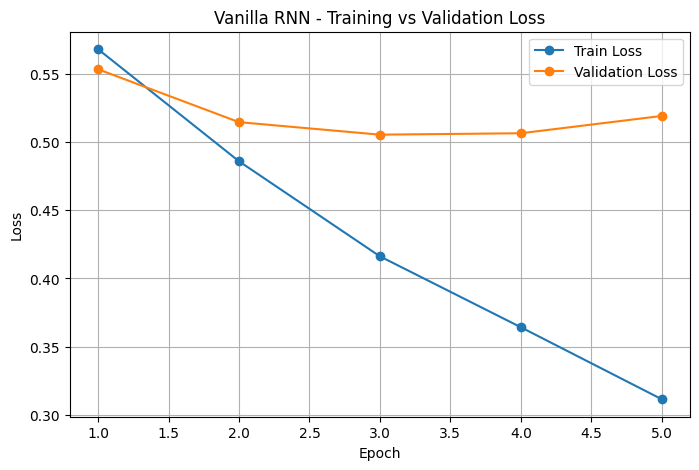

In [221]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Vanilla RNN - Training vs Validation Loss")

plt.legend()
plt.grid()

plt.show()

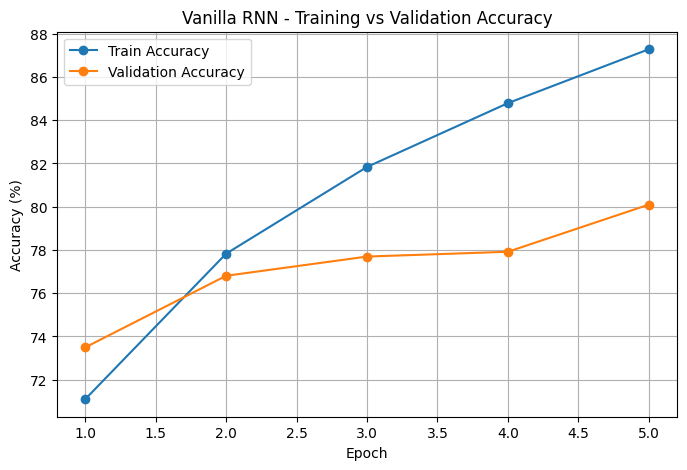

In [222]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [acc * 100 for acc in history["train_acc"]],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs,
    [acc * 100 for acc in history["val_acc"]],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Vanilla RNN - Training vs Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

In [223]:
model.load_state_dict(
    torch.load(
        "best_rnn_model.pt",
        map_location=device
    )
)

model = model.to(device)

model.eval()

RNNClassifier(
  (embedding): Embedding(27084, 100, padding_idx=0)
  (rnn): RNN(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

# Check on test data

In [224]:
test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: {test_acc * 100:.2f}%"
)

Test Loss: 0.5187
Test Accuracy: 76.64%


In [252]:
def predict_sentiment(
    text,
    model,
    word_to_idx,
    max_length,
    device
):

    model.eval()

    tokens = Final_Tokenizer(text)

    length = min(
        len(tokens),
        max_length
    )

    input_ids = preprocess_text(
        text,
        word_to_idx,
        max_length
    )

    input_tensor = torch.tensor(
        input_ids,
        dtype=torch.long
    ).unsqueeze(0)

    length_tensor = torch.tensor(
        [length],
        dtype=torch.long
    )

    input_tensor = input_tensor.to(device)

    with torch.no_grad():

        logit = model(
            input_tensor,
            length_tensor
        )

        positive_probability = torch.sigmoid(
            logit
        ).item()

    negative_probability = (
        1 - positive_probability
    )

    prediction = (
        1
        if positive_probability >= 0.5
        else 0
    )

    sentiment = (
        "Positive"
        if prediction == 1
        else "Negative"
    )

    return (
        sentiment,
        positive_probability,
        negative_probability
    )

In [283]:
sample = """
I expected this movie to be terrible,
but surprisingly I really enjoyed it.
"""

sentiment, p , n = predict_sentiment(
    sample,
    model,
    word_to_idx,
    MAX_LENGTH,
    device
)

print("Review:")
print(sample)

print()

print("Prediction:", sentiment)

print(
    f"Positive Probability: {p:.4f}"
)
print(
    f"Negative Probability: {n:.4f}"
)

Review:

I expected this movie to be terrible,
but surprisingly I really enjoyed it.


Prediction: Negative
Positive Probability: 0.3958
Negative Probability: 0.6042


- RNN baseline showed reasonable performance, but recurrent neural networks can struggle with long-term dependencies

# LSTM Model
- LSTM networks introduce a memory cell and gating mechanisms that help preserve important information over longer sequences.

In [237]:
class LSTMClassifier(nn.Module):

    def __init__(self,vocab_size,embedding_dim, hidden_size,num_layers,pad_idx):

        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self,x,lengths):
        # [batch, seq_len]
        #        ↓
        # [batch, seq_len, embedding_dim]
        embedded = self.embedding(x)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )
        _, (hidden, cell) = self.lstm(
            packed
        )
        final_hidden = hidden[-1]#last layer
        
        logits = self.fc(final_hidden)


        return logits


In [240]:
lstm_model = LSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    pad_idx=word_to_idx[PAD_TOKEN]

)

lstm_model = lstm_model.to(device)

print(lstm_model)

LSTMClassifier(
  (embedding): Embedding(27084, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [241]:
print(
    "Trainable Parameters:",
    count_parameters(lstm_model)
)

Trainable Parameters: 2826289


In [242]:
inputs, labels, lengths = next(
    iter(train_loader)
)

inputs = inputs.to(device)

with torch.no_grad():

    logits = lstm_model(
        inputs,
        lengths
    )

print(
    "Input shape:",
    inputs.shape
)

print(
    "Lengths shape:",
    lengths.shape
)

print(
    "Logits shape:",
    logits.shape
)

print(
    "\nFirst 5 logits:"
)

print(
    logits[:5]
)

print(
    "\nFirst 5 probabilities:"
)

print(
    torch.sigmoid(logits[:5])
)

Input shape: torch.Size([32, 500])
Lengths shape: torch.Size([32])
Logits shape: torch.Size([32, 1])

First 5 logits:
tensor([[ 0.0538],
        [ 0.0926],
        [-0.0016],
        [ 0.0397],
        [-0.0622]])

First 5 probabilities:
tensor([[0.5134],
        [0.5231],
        [0.4996],
        [0.5099],
        [0.4845]])


In [246]:
lstm_criterion = nn.BCEWithLogitsLoss()

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=LEARNING_RATE
)


In [247]:
lstm_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}
best_lstm_val_loss = float("inf")

In [249]:

LSTM_EPOCHS=2

for epoch in range(LSTM_EPOCHS):

    start = time.time()

    train_loss, train_acc = train_one_epoch(
        lstm_model,
        train_loader,
        lstm_criterion,
        lstm_optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        lstm_model,
        val_loader,
        lstm_criterion,
        device
    )

    end = time.time()


    lstm_history["train_loss"].append(
        train_loss
    )

    lstm_history["train_acc"].append(
        train_acc
    )

    lstm_history["val_loss"].append(
        val_loss
    )

    lstm_history["val_acc"].append(
        val_acc
    )


    if val_loss < best_lstm_val_loss:

        best_lstm_val_loss = val_loss

        torch.save(
            lstm_model.state_dict(),
            "best_lstm_model.pt"
        )


    print(
        f"Time: {(end - start) / 60:.2f} minutes"
    )

    print(
        f"Epoch {epoch + 1}/{LSTM_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc * 100:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc * 100:.2f}%"
    )

    print("-" * 60)

Time: 17.25 minutes
Epoch 1/2
Train Loss: 0.4331 | Train Accuracy: 80.62%
Val Loss: 0.7105 | Val Accuracy: 77.13%
------------------------------------------------------------
Time: 18.60 minutes
Epoch 2/2
Train Loss: 0.3146 | Train Accuracy: 87.36%
Val Loss: 0.4125 | Val Accuracy: 83.99%
------------------------------------------------------------


In [250]:
lstm_model.load_state_dict(
    torch.load(
        "best_lstm_model.pt",
        map_location=device
    )
)

lstm_model = lstm_model.to(device)

lstm_model.eval()

LSTMClassifier(
  (embedding): Embedding(27084, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

In [251]:
lstm_test_loss, lstm_test_acc = evaluate(
    lstm_model,
    test_loader,
    lstm_criterion,
    device
)

print("=" * 50)
print("LSTM FINAL TEST RESULTS")
print("=" * 50)

print(
    f"Test Loss: {lstm_test_loss:.4f}"
)

print(
    f"Test Accuracy: {lstm_test_acc * 100:.2f}%"
)

LSTM FINAL TEST RESULTS
Test Loss: 0.4310
Test Accuracy: 83.56%


In [282]:
tricky_sample = """
I expected this movie to be terrible,
but surprisingly I really enjoyed it.
"""

sentiment, positive_prob, negative_prob = predict_sentiment(
    tricky_sample,
    lstm_model,
    word_to_idx,
    MAX_LENGTH,
    device
)

print("Review:")
print(tricky_sample)

print()

print(
    "Prediction:",
    sentiment
)

print(
    f"Positive Probability: {positive_prob:.4f}"
)

print(
    f"Negative Probability: {negative_prob:.4f}"
)

Review:

I expected this movie to be terrible,
but surprisingly I really enjoyed it.


Prediction: Negative
Positive Probability: 0.2795
Negative Probability: 0.7205


# GRU Model

In [263]:
class GRUClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_size,
        num_layers,
        pad_idx
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            1
        )


    def forward(self, x, lengths):

        embedded = self.embedding(x)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(
            packed
        )

        final_hidden = hidden[-1]

        logits = self.fc(
            final_hidden
        )

        return logits

In [269]:
gru_model = GRUClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    pad_idx=word_to_idx[PAD_TOKEN]
)

gru_model = gru_model.to(device)

In [270]:
print(gru_model)

print(
    "\nTrainable Parameters:",
    count_parameters(gru_model)
)

GRUClassifier(
  (embedding): Embedding(27084, 100, padding_idx=0)
  (gru): GRU(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

Trainable Parameters: 2796849


In [271]:
inputs, labels, lengths = next(
    iter(train_loader)
)

inputs = inputs.to(device)

with torch.no_grad():

    logits = gru_model(
        inputs,
        lengths
    )

print(
    "Input shape:",
    inputs.shape
)

print(
    "Lengths shape:",
    lengths.shape
)

print(
    "Logits shape:",
    logits.shape
)

print(
    "\nFirst 5 probabilities:"
)

print(
    torch.sigmoid(logits[:5])
)

Input shape: torch.Size([32, 500])
Lengths shape: torch.Size([32])
Logits shape: torch.Size([32, 1])

First 5 probabilities:
tensor([[0.4612],
        [0.5485],
        [0.5628],
        [0.5379],
        [0.5233]])


In [272]:
gru_criterion = nn.BCEWithLogitsLoss()

gru_optimizer = torch.optim.Adam(
    gru_model.parameters(),
    lr=LEARNING_RATE
)

In [273]:
gru_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_gru_val_loss = float("inf")

In [276]:
GRU_EPOCHS = 4

for epoch in range(GRU_EPOCHS):

    start = time.time()

    train_loss, train_acc = train_one_epoch(
        gru_model,
        train_loader,
        gru_criterion,
        gru_optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        gru_model,
        val_loader,
        gru_criterion,
        device
    )

    end = time.time()

    gru_history["train_loss"].append(train_loss)
    gru_history["train_acc"].append(train_acc)
    gru_history["val_loss"].append(val_loss)
    gru_history["val_acc"].append(val_acc)

    if val_loss < best_gru_val_loss:

        best_gru_val_loss = val_loss

        torch.save(
            gru_model.state_dict(),
            "best_gru_model.pt"
        )

    print(
        f"Time: {(end - start) / 60:.2f} minutes"
    )

    print(
        f"Epoch {epoch + 1}/{GRU_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc * 100:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc * 100:.2f}%"
    )

    print("-" * 60)

Time: 12.41 minutes
Epoch 1/4
Train Loss: 0.3570 | Train Accuracy: 84.84%
Val Loss: 0.3166 | Val Accuracy: 86.86%
------------------------------------------------------------
Time: 12.76 minutes
Epoch 2/4
Train Loss: 0.2177 | Train Accuracy: 91.61%
Val Loss: 0.2966 | Val Accuracy: 87.87%
------------------------------------------------------------
Time: 13.66 minutes
Epoch 3/4
Train Loss: 0.1324 | Train Accuracy: 95.34%
Val Loss: 0.3269 | Val Accuracy: 87.51%
------------------------------------------------------------
Time: 14.67 minutes
Epoch 4/4
Train Loss: 0.0711 | Train Accuracy: 97.82%
Val Loss: 0.3602 | Val Accuracy: 87.97%
------------------------------------------------------------


In [277]:
gru_model.load_state_dict(
    torch.load(
        "best_gru_model.pt",
        map_location=device
    )
)

gru_model = gru_model.to(device)

gru_model.eval()

GRUClassifier(
  (embedding): Embedding(27084, 100, padding_idx=0)
  (gru): GRU(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

In [278]:
gru_test_loss, gru_test_acc = evaluate(
    gru_model,
    test_loader,
    gru_criterion,
    device
)

print("=" * 50)
print("GRU FINAL TEST RESULTS")
print("=" * 50)

print(f"Test Loss: {gru_test_loss:.4f}")
print(f"Test Accuracy: {gru_test_acc * 100:.2f}%")

GRU FINAL TEST RESULTS
Test Loss: 0.3069
Test Accuracy: 87.15%


In [281]:
tricky_sample = """
I expected this movie to be terrible,
but surprisingly I really enjoyed it.
"""

sentiment, positive_prob, negative_prob = predict_sentiment(
    tricky_sample,
    gru_model,
    word_to_idx,
    MAX_LENGTH,
    device
)

print("Review:")
print(tricky_sample)

print()

print("Prediction:", sentiment)
print(f"Positive Probability: {positive_prob:.4f}")
print(f"Negative Probability: {negative_prob:.4f}")

Review:

I expected this movie to be terrible,
but surprisingly I really enjoyed it.


Prediction: Positive
Positive Probability: 0.5639
Negative Probability: 0.4361


# Bidirectional LSTM

In [284]:
class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_size,
        num_layers,
        pad_idx
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            #here the feature we add
            bidirectional=True
        )
        # ht=>
        # <= ht      
        self.fc = nn.Linear(
            hidden_size * 2,
            1
        )


    def forward(self, x, lengths):

        embedded = self.embedding(x)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, cell) = self.lstm(
            packed
        )

        forward_hidden = hidden[-2]

        backward_hidden = hidden[-1]

        final_hidden = torch.cat(
            (
                forward_hidden,
                backward_hidden
            ),
            dim=1
        )

        logits = self.fc(
            final_hidden
        )

        return logits

In [286]:
bilstm_model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    pad_idx=word_to_idx[PAD_TOKEN]
)

bilstm_model = bilstm_model.to(device)

In [287]:
print(bilstm_model)

print(
    "\nTrainable Parameters:",
    count_parameters(bilstm_model)
)

BiLSTMClassifier(
  (embedding): Embedding(27084, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)

Trainable Parameters: 2944177


In [288]:
inputs, labels, lengths = next(
    iter(train_loader)
)

inputs = inputs.to(device)

with torch.no_grad():

    logits = bilstm_model(
        inputs,
        lengths
    )

print(
    "Input shape:",
    inputs.shape
)

print(
    "Lengths shape:",
    lengths.shape
)

print(
    "Logits shape:",
    logits.shape
)

print(
    "\nFirst 5 probabilities:"
)

print(
    torch.sigmoid(logits[:5])
)

Input shape: torch.Size([32, 500])
Lengths shape: torch.Size([32])
Logits shape: torch.Size([32, 1])

First 5 probabilities:
tensor([[0.4612],
        [0.5249],
        [0.4750],
        [0.5286],
        [0.4693]])


In [289]:
bilstm_criterion = nn.BCEWithLogitsLoss()

bilstm_optimizer = torch.optim.Adam(
    bilstm_model.parameters(),
    lr=LEARNING_RATE
)

In [291]:
bilstm_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_bilstm_val_loss = float("inf")

In [295]:
BILSTM_EPOCHS = 1


for epoch in range(BILSTM_EPOCHS):

    start = time.time()

    train_loss, train_acc = train_one_epoch(
        bilstm_model,
        train_loader,
        bilstm_criterion,
        bilstm_optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        bilstm_model,
        val_loader,
        bilstm_criterion,
        device
    )

    end = time.time()

    bilstm_history["train_loss"].append(
        train_loss
    )

    bilstm_history["train_acc"].append(
        train_acc
    )

    bilstm_history["val_loss"].append(
        val_loss
    )

    bilstm_history["val_acc"].append(
        val_acc
    )

    if val_loss < best_bilstm_val_loss:

        best_bilstm_val_loss = val_loss

        torch.save(
            bilstm_model.state_dict(),
            "best_bilstm_model.pt"
        )

    print(
        f"Time: {(end - start) / 60:.2f} minutes"
    )

    print(
        f"Epoch {epoch + 1}/{BILSTM_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc * 100:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc * 100:.2f}%"
    )

    print("-" * 60)

Time: 35.14 minutes
Epoch 1/1
Train Loss: 0.1873 | Train Accuracy: 92.72%
Val Loss: 0.3762 | Val Accuracy: 86.27%
------------------------------------------------------------


In [296]:
bilstm_model.load_state_dict(
    torch.load(
        "best_bilstm_model.pt",
        map_location=device
    )
)

bilstm_model = bilstm_model.to(device)
bilstm_model.eval()

BiLSTMClassifier(
  (embedding): Embedding(27084, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)

In [298]:
bilstm_test_loss, bilstm_test_acc = evaluate(
    bilstm_model,
    test_loader,
    bilstm_criterion,
    device
)

print("=" * 50)
print("BiLSTM FINAL TEST RESULTS")
print("=" * 50)

print(f"Test Loss: {bilstm_test_loss:.4f}")
print(f"Test Accuracy: {bilstm_test_acc * 100:.2f}%")

BiLSTM FINAL TEST RESULTS
Test Loss: 0.3592
Test Accuracy: 84.64%


In [299]:
tricky_sample = """
I expected this movie to be terrible,
but surprisingly I really enjoyed it.
"""

sentiment, positive_prob, negative_prob = predict_sentiment(
    tricky_sample,
    bilstm_model,
    word_to_idx,
    MAX_LENGTH,
    device
)

print("Review:")
print(tricky_sample)

print()

print("Prediction:", sentiment)
print(f"Positive Probability: {positive_prob:.4f}")
print(f"Negative Probability: {negative_prob:.4f}")


Review:

I expected this movie to be terrible,
but surprisingly I really enjoyed it.


Prediction: Positive
Positive Probability: 0.8222
Negative Probability: 0.1778


# The comparison includes:

- Test Loss
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- Number of trainable parameters
- Training time
- Qualitative behavior on a challenging sentiment-reversal example

In [ ]:
def collect_predictions(model,loader,device):
    #remove it??
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for inputs, labels, lengths in loader:

            inputs = inputs.to(device)

            logits = model(
                inputs,
                lengths
            )

            probabilities = torch.sigmoid(
                logits
            ).squeeze(1)

            predictions = (
                probabilities >= 0.5
            ).long()

            all_labels.extend(
                labels.cpu().tolist()
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().tolist()
            )

    return (all_labels,all_predictions,all_probabilities)

In [301]:
rnn_y_true, rnn_y_pred, rnn_probs = collect_predictions(
    model,
    test_loader,
    device
)

lstm_y_true, lstm_y_pred, lstm_probs = collect_predictions(
    lstm_model,
    test_loader,
    device
)

gru_y_true, gru_y_pred, gru_probs = collect_predictions(
    gru_model,
    test_loader,
    device
)

bilstm_y_true, bilstm_y_pred, bilstm_probs = collect_predictions(
    bilstm_model,
    test_loader,
    device
)

In [302]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score, f1_score,confusion_matrix,classification_report)

def calculate_metrics(y_true,y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred
    )

    recall = recall_score(
        y_true,
        y_pred
    )

    f1 = f1_score(
        y_true,
        y_pred
    )

    return (
        accuracy,
        precision,
        recall,
        f1
    )

In [303]:
rnn_metrics = calculate_metrics(
    rnn_y_true,
    rnn_y_pred
)

lstm_metrics = calculate_metrics(
    lstm_y_true,
    lstm_y_pred
)

gru_metrics = calculate_metrics(
    gru_y_true,
    gru_y_pred
)

bilstm_metrics = calculate_metrics(
    bilstm_y_true,
    bilstm_y_pred
)

In [304]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": [
        "Vanilla RNN",
        "LSTM",
        "GRU",
        "BiLSTM"
    ],
    # i didnot put epochs all the same because the time was diffrence for each one
    "Epochs": [
        6,
        3,
        5,
        4
    ],
    # least Test loss between all epochs for every model
    "Test Loss": [
        0.5187,
        0.4310,
        0.3069,
        0.3592
    ],

    "Accuracy": [
        rnn_metrics[0],
        lstm_metrics[0],
        gru_metrics[0],
        bilstm_metrics[0]
    ],

    "Precision": [
        rnn_metrics[1],
        lstm_metrics[1],
        gru_metrics[1],
        bilstm_metrics[1]
    ],

    "Recall": [
        rnn_metrics[2],
        lstm_metrics[2],
        gru_metrics[2],
        bilstm_metrics[2]
    ],

    "F1 Score": [
        rnn_metrics[3],
        lstm_metrics[3],
        gru_metrics[3],
        bilstm_metrics[3]
    ]
})

comparison_df

,Model,Epochs,Test Loss,Accuracy,Precision,Recall,F1 Score
0,Vanilla RNN,6,0.5187,0.766380,0.768851,0.763907,0.766371
1,LSTM,3,0.4310,0.835611,0.895339,0.761254,0.822870
2,GRU,5,0.3069,0.871497,0.863062,0.884084,0.873446
3,BiLSTM,4,0.3592,0.846377,0.839283,0.858039,0.848557


In [305]:
comparison_df["Parameters"] = [
    count_parameters(model),
    count_parameters(lstm_model),
    count_parameters(gru_model),
    count_parameters(bilstm_model)
]
comparison_df

,Model,Epochs,Test Loss,Accuracy,Precision,Recall,F1 Score,Parameters
0,Vanilla RNN,6,0.5187,0.766380,0.768851,0.763907,0.766371,2737969
1,LSTM,3,0.4310,0.835611,0.895339,0.761254,0.822870,2826289
2,GRU,5,0.3069,0.871497,0.863062,0.884084,0.873446,2796849
3,BiLSTM,4,0.3592,0.846377,0.839283,0.858039,0.848557,2944177


- RNN achieved the lowest overall performance even it the most epochs because: 
- Vanishing gradients
- Exploding gradients
- Difficulty preserving long-term information

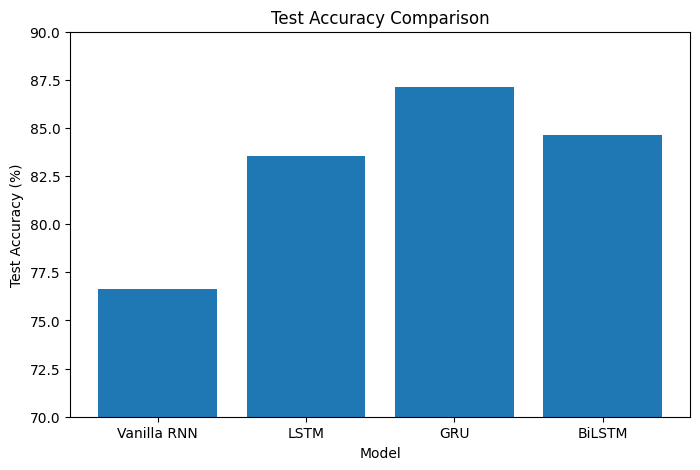

In [306]:
#Accuracy vis

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"] * 100
)

plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy Comparison")

plt.ylim(70, 90)

plt.show()

- 
Despite having a simpler gating mechanism than LSTM 
GRU provided the strongest Performance for (Accuracy) , but there a problem with reversal sentiment

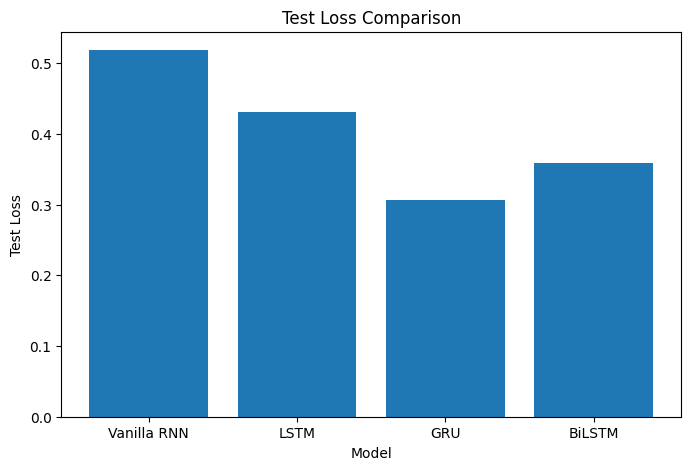

In [307]:
#Test loss
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Loss"]
)

plt.xlabel("Model")
plt.ylabel("Test Loss")
plt.title("Test Loss Comparison")

plt.show()

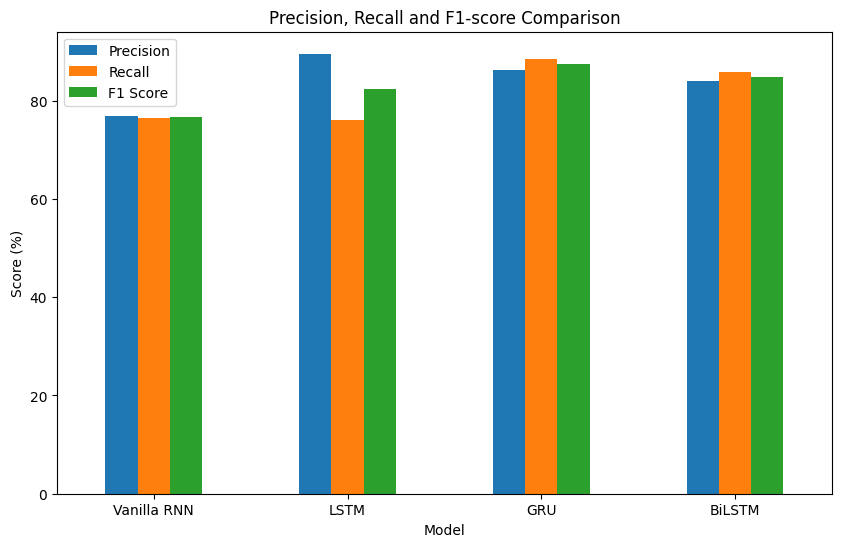

In [308]:
metrics_plot = comparison_df.set_index(
    "Model"
)[
    [
        "Precision",
        "Recall",
        "F1 Score"
    ]
] * 100

metrics_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Score (%)")
plt.title(
    "Precision, Recall and F1-score Comparison"
)

plt.xticks(
    rotation=0
)

plt.legend()

plt.show()

In [309]:
from sklearn.metrics import ConfusionMatrixDisplay

def plot_confusion_matrix(y_true,y_pred,model_name):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Negative",
            "Positive"
        ]
    )

    display.plot()

    plt.title(
        f"{model_name} - Confusion Matrix"
    )

    plt.show()

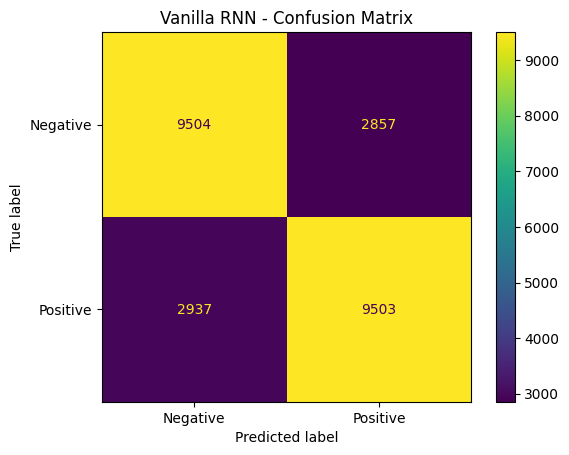

In [310]:
plot_confusion_matrix(
    rnn_y_true,
    rnn_y_pred,
    "Vanilla RNN"
)

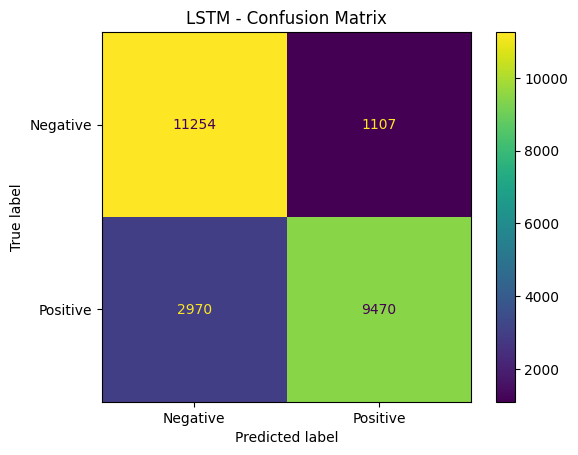

In [311]:
plot_confusion_matrix(
    lstm_y_true,
    lstm_y_pred,
    "LSTM"
)

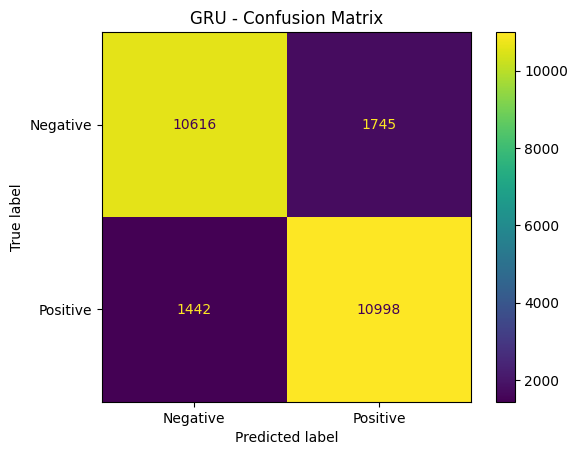

In [312]:
plot_confusion_matrix(
    gru_y_true,
    gru_y_pred,
    "GRU"
)

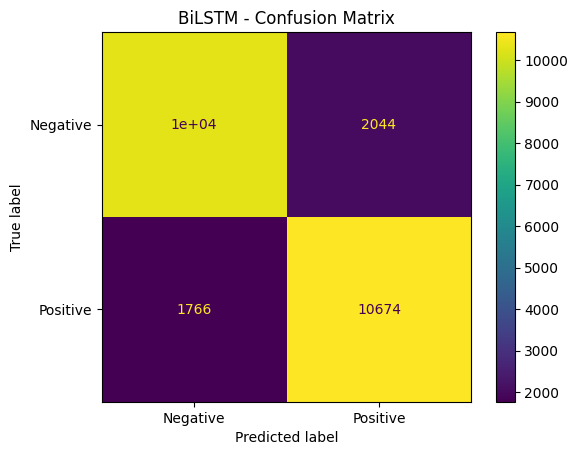

In [313]:
plot_confusion_matrix(
    bilstm_y_true,
    bilstm_y_pred,
    "BiLSTM"
)

In [ ]:

print(
    classification_report(
        gru_y_true,
        gru_y_pred,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87     12361
    Positive       0.86      0.88      0.87     12440

    accuracy                           0.87     24801
   macro avg       0.87      0.87      0.87     24801
weighted avg       0.87      0.87      0.87     24801



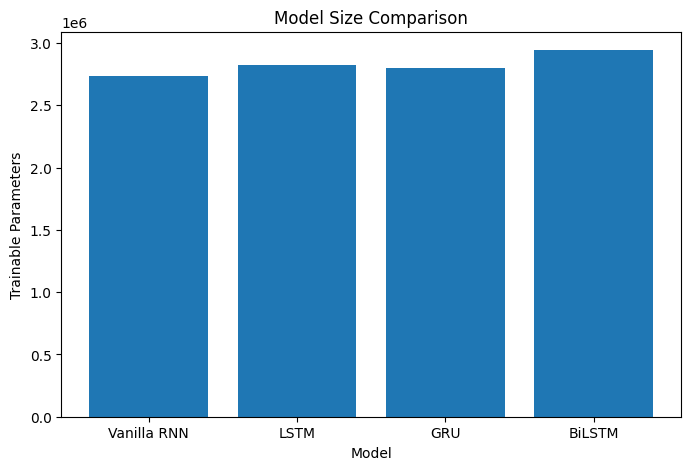

In [315]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Parameters"]
)

plt.xlabel("Model")
plt.ylabel("Trainable Parameters")
plt.title("Model Size Comparison")

plt.show()

**BiLSTM has the highest number of parameters, and this makes sense.**

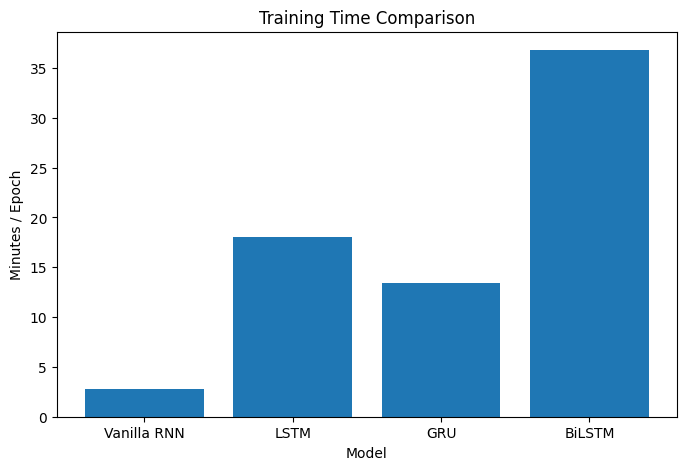

In [319]:
training_time_df = pd.DataFrame({
    "Model": [
        "Vanilla RNN",
        "LSTM",
        "GRU",
        "BiLSTM"
    ],

    "Approx Time": [
        2.8,
        18.0,
        13.4,
        36.8
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(
    training_time_df["Model"],
    training_time_df["Approx Time"]
)

plt.xlabel("Model")
plt.ylabel("Minutes / Epoch")
plt.title("Training Time Comparison")

plt.show()

**BiLstm taking more time because it work on two ways**

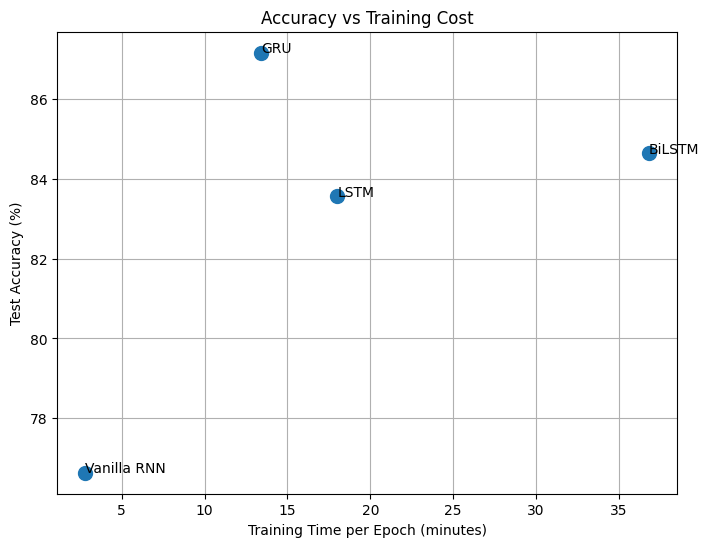

In [320]:
efficiency_df = pd.DataFrame({
    "Model": [
        "Vanilla RNN",
        "LSTM",
        "GRU",
        "BiLSTM"
    ],

    "Accuracy": [
        76.64,
        83.56,
        87.15,
        84.64
    ],

    "Time": [
        2.8,
        18.0,
        13.4,
        36.8
    ]
})
plt.figure(figsize=(8, 6))

plt.scatter(
    efficiency_df["Time"],
    efficiency_df["Accuracy"],
    s=100
)

for _, row in efficiency_df.iterrows():

    plt.annotate(
        row["Model"],
        (
            row["Time"],
            row["Accuracy"]
        )
    )

plt.xlabel("Training Time per Epoch (minutes)")
plt.ylabel("Test Accuracy (%)")

plt.title(
    "Accuracy vs Training Cost"
)

plt.grid()

plt.show()

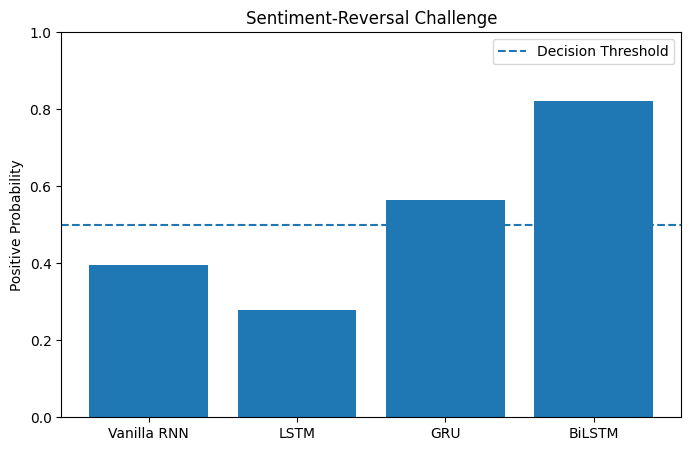

In [321]:
#tricky sample vis

tricky_results = pd.DataFrame({
    "Model": [
        "Vanilla RNN",
        "LSTM",
        "GRU",
        "BiLSTM"
    ],

    "Positive Probability": [
        0.3958,
        0.2795,
        0.5639,
        0.8222
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(
    tricky_results["Model"],
    tricky_results["Positive Probability"]
)

plt.axhline(
    y=0.5,
    linestyle="--",
    label="Decision Threshold"
)

plt.ylabel(
    "Positive Probability"
)

plt.title(
    "Sentiment-Reversal Challenge"
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.show()

# Conclusion

- The experiments demonstrate the importance of recurrent architecture design for sentiment classification.

- The Vanilla RNN provided a useful baseline but struggled to model long-term dependencies effectively.

- LSTM substantially improved performance by introducing a gated memory mechanism.

- GRU produced the strongest overall results, achieving the highest test accuracy and lowest test loss while requiring less training time than LSTM and BiLSTM.

- BiLSTM did not achieve the highest overall accuracy, but its bidirectional representation performed particularly well on a challenging sentiment-reversal example.

Therefore, the experiments highlight an important machine-learning principle:

**Increasing architectural complexity does not necessarily guarantee better overall performance.**

Model selection should consider several factors together:

- Generalization performance
- Computational cost
- Model complexity
- Behavior on difficult examples